# Projeto Steam Games -  EDA_Portfólio

Olá a todos! Sejam bem-vindos ao meu projeto Steam Games.

Dando sequência ao trabalho iniciado na etapa de ETL, o objetivo desta fase é realizar uma Análise Exploratória de Dados (EDA) em Python. Utilizando as bibliotecas Pandas, Matplotlib e Seaborn, vou extrair insights, identificar padrões e tendências do mercado, além de aprimorar minhas habilidades na construção de visualizações gráficas.

*"Esta Análise Exploratória de Dados (EDA) foi desenvolvida a partir de um conjunto de dados em formato Excel (.xlsx), previamente limpo e tratado na etapa de ETL. Utilizando as bibliotecas Pandas, Matplotlib e Seaborn, foram construídas visualizações estratégicas para extrair insights relevantes sobre o mercado."*

# - Importação, Definição e Carregamento do DataFrame

Neste primeiro momento, fiz a importação de algumas bibliotecas para a realização das atividades. Em seguida, realizei a definição e o carregamento do DataFrame.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configurando o estilo visual dos gráficos
sns.set_theme(style="whitegrid", palette="viridis")

# Carregando o dataset e preparando colunas auxiliares
df = pd.read_excel("Steam_Dataset_Limpo-ETL.xlsx")
df['Price_Formatado'] = df['Price'] / 100
df['Release date'] = pd.to_datetime(df['Release date'], errors='coerce')
df['Release Year'] = df['Release date'].dt.year

# 1. A Explosão e Saturação do Mercado
O gráfico abaixo analisa o volume de lançamentos na Steam na última década (2010 a 2025) para entendermos o ritmo de crescimento da plataforma.

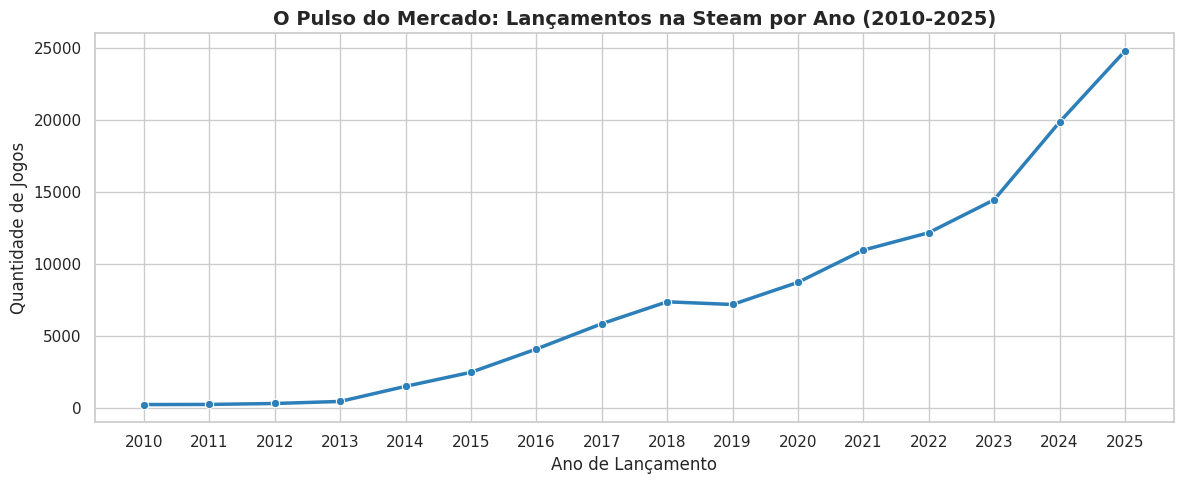

In [2]:
plt.figure(figsize=(12, 5))

df_anos = df[(df['Release Year'] >= 2010) & (df['Release Year'] <= 2025)]
lancamentos_por_ano = df_anos['Release Year'].value_counts().sort_index()

sns.lineplot(x=lancamentos_por_ano.index, y=lancamentos_por_ano.values, marker='o', linewidth=2.5, color="#2c7fb8")

plt.title('O Pulso do Mercado: Lançamentos na Steam por Ano (2010-2025)', fontsize=14, weight='bold')
plt.xlabel('Ano de Lançamento', fontsize=12)
plt.ylabel('Quantidade de Jogos', fontsize=12)
plt.xticks(range(2010, 2026))
plt.tight_layout()
plt.show()

### **Insight 1:**

A análise do gráfico revela insights valiosos sobre o ritmo de lançamentos na plataforma. O primeiro grande destaque vai para os anos iniciais (2010 a 2013), que apresentam um volume quase inexpressivo de novos jogos se comparado aos dias atuais. Segundo dados do SteamDB, aproximadamente, 1.295 títulos foram lançados nesse intervalo de quatro anos.

Esse 'gargalo' inicial não foi um acidente de mercado, mas sim o resultado das políticas da própria plataforma na época, que logo foram substituídas para dar início à explosão de lançamentos:

  1. **A Era da Curadoria Rígida (Gatekeeping):** Até 2012, a Valve operava como uma curadora estrita. A entrada na loja não era livre, os funcionários da empresa escolhiam a dedo quais jogos tinham o padrão exigido para serem comercializados na plataforma, o que limitava drasticamente o volume de novos títulos.
  2. **A Abertura das Portas (Steam Greenlight e Steam Direct):** O cenário começou a mudar em agosto de 2012 com o lançamento do Steam Greenlight, transferindo o poder de aprovação para a votação da comunidade. Posteriormente, o Steam Direct (2017) removeu de vez as barreiras, permitindo que qualquer desenvolvedor publicasse seu jogo mediante o pagamento de uma taxa.

Dali em diante, a remoção das barreiras da loja se uniu a fatores externos poderosos: A popularização de motores gráficos acessíveis (como Unity e Unreal), o boom histórico do mercado Indie e, mais recentemente, a aceleração de desenvolvimento via Inteligências Artificiais generativas. Esses elementos combinados explicam o crescimento exponencial e contínuo que transformou a Steam na potência saturada e diversificada que vemos hoje.






# 2. O Mito do Preço vs. Engajamento
A hipótese testada aqui é: "Jogadores passam mais tempo em jogos pelos quais pagaram mais caro?".

/tmp/ipykernel_1758/1274323712.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=engajamento_faixa, x='Faixa_Preco', y='Horas_Jogadas', palette='Blues_d')


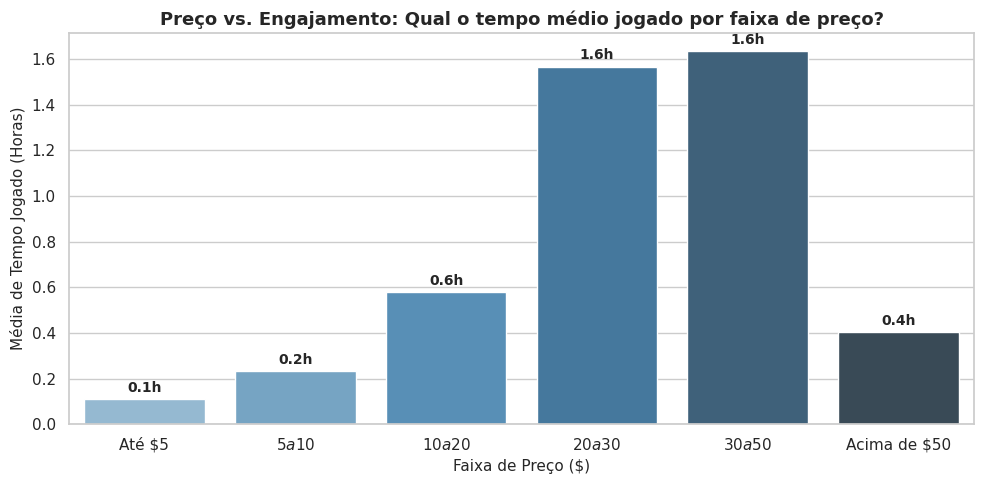

In [3]:
plt.figure(figsize=(10, 5))

# 1. Preparando dados de jogos pagos e convertendo tempo para horas
df_pagos = df[df['Price_Formatado'] > 0].copy()
df_pagos['Horas_Jogadas'] = df_pagos['Median playtime forever'] / 60

# 2. Criando faixas de preço claras
faixas_preco = [0, 5, 10, 20, 30, 50, 1000]
rotulos_preco = ['Até $5', '$5 a $10', '$10 a $20', '$20 a $30', '$30 a $50', 'Acima de $50']
df_pagos['Faixa_Preco'] = pd.cut(df_pagos['Price_Formatado'], bins=faixas_preco, labels=rotulos_preco)

# 3. Calculando a média de horas por faixa
engajamento_faixa = df_pagos.groupby('Faixa_Preco', observed=True)['Horas_Jogadas'].mean().reset_index()

# 4. Plotando o gráfico de barras
ax = sns.barplot(data=engajamento_faixa, x='Faixa_Preco', y='Horas_Jogadas', palette='Blues_d')

plt.title('Preço vs. Engajamento: Qual o tempo médio jogado por faixa de preço?', fontsize=13, weight='bold')
plt.xlabel('Faixa de Preço ($)', fontsize=11)
plt.ylabel('Média de Tempo Jogado (Horas)', fontsize=11)

# Adicionando rótulos com os valores exatos em cima das barras
for p in ax.patches:
    altura = p.get_height()
    ax.annotate(f'{altura:.1f}h',
                (p.get_x() + p.get_width() / 2., altura),
                ha='center', va='bottom', fontsize=10, weight='bold', xytext=(0, 3),
                textcoords='offset points')

plt.tight_layout()
plt.show()

### **Insight 2:**

A análise do gráfico desconstrói a ideia de que "quanto mais caro o jogo, mais tempo ele será jogado". Na verdade, a relação entre o preço e a retenção forma uma curva de sino quase perfeita, com um pico muito claro nas faixas intermediárias de valor.

*   O Início Tímido (Até $10): Jogos nas faixas mais baratas apresentam as menores médias de tempo jogado, registrando apenas 0.1h e 0.2h, respectivamente. Isso reflete a natureza desses produtos, sendo experiências curtas, jogos casuais ou compras por impulso em grandes promoções que acabam esquecidas na biblioteca.

*   A Retenção ($20 a $50): O engajamento atinge seu ápice absoluto nas faixas médias, ambas cravando a média máxima de 1.6 horas. Este é o território dominado por jogos Premium Indies robustos, títulos AA e grandes sucessos de sobrevivência/mundo aberto. Eles entregam um excelente custo-benefício, prendendo os jogadores com sistemas profundos e alta rejogabilidade.

*   A Queda dos Gigantes (Acima de $50): O dado mais surpreendente é a queda brusca na faixa dos jogos mais caros, que despenca para uma média de apenas 0.4h. Isso indica que grandes lançamentos AAA podem até gerar picos de venda, mas a vasta maioria dos jogadores não chega a investir dezenas de horas neles, seja por falta de tempo, por serem experiências lineares (com começo, meio e fim rápidos), ou pelo fato de muitos comprarem no hype e não jogarem de imediato.





# 3. O "Vale da Morte" Indie (Pico de Atenção por Preço)
Como a atenção simultânea dos jogadores se divide entre as diferentes faixas de preço cobradas na loja?

/tmp/ipykernel_1758/1871082377.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=ccu_por_categoria, x='Price_Tier', y='Peak CCU', palette='magma')


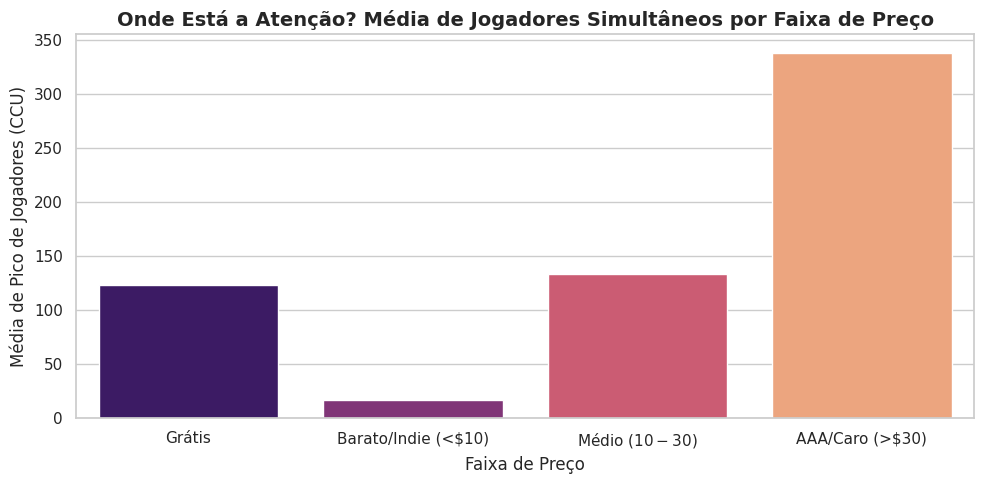

In [4]:
plt.figure(figsize=(10, 5))

bins = [-1, 0.01, 10, 30, 1000]
labels = ['Grátis', 'Barato/Indie (<$10)', 'Médio ($10-$30)', 'AAA/Caro (>$30)']
df['Price_Tier'] = pd.cut(df['Price_Formatado'], bins=bins, labels=labels)

ccu_por_categoria = df.groupby('Price_Tier', observed=True)['Peak CCU'].mean().reset_index()
sns.barplot(data=ccu_por_categoria, x='Price_Tier', y='Peak CCU', palette='magma')

plt.title('Onde Está a Atenção? Média de Jogadores Simultâneos por Faixa de Preço', fontsize=14, weight='bold')
plt.xlabel('Faixa de Preço', fontsize=12)
plt.ylabel('Média de Pico de Jogadores (CCU)', fontsize=12)
plt.tight_layout()
plt.show()

### **Insight 3:**

A análise do gráfico revela a forte relação entre a faixa de preço de um jogo e o tempo que ele consegue reter a atenção do usuário. O primeiro grande destaque vai para os títulos Baratos/Indie (Até $10), que apresentam um volume de engajamento quase inexpressivo em comparação aos demais. Isso não é necessariamente um defeito, mas um reflexo da natureza desses projetos (que em sua maioria) costumam ser experiências focadas, lineares e de curta duração, sem mecânicas criadas para prender o jogador por meses.

Avançando para as faixas intermediárias, notamos um comportamento sólido tanto nos Jogos Grátis quanto nos de Preço Médio ($10 a $30). Os gratuitos mantêm médias altas de retenção por serem, em sua esmagadora maioria, experiências Multiplayers, projetadas exatamente para o uso contínuo. Já a faixa Média representa o "ponto de equilíbrio" da plataforma. É neste valor que habitam os grandes sucessos Premium Indies (como roguelikes de alta rejogabilidade) e os populares jogos de Sobrevivência/Co-op. São títulos que entregam uma profundidade mecânica que muitas vezes rivaliza ou supera grandes produções industriais.

Por fim, os Títulos AAA/Caros (Acima de $50) dominam o topo do engajamento. Tratam-se de superproduções e franquias consagradas que oferecem campanhas densas, mundos abertos massivos ou modos online complexos. Além da escala do conteúdo, há um fator psicológico atrelado ao preço pelo alto investimento inicial, criando um viés de comprometimento. O jogador que adquire um título nesse valor (seja no lançamento ou aguardando grandes promoções) tende a extrair o máximo de horas possíveis para justificar o valor investido, garantindo uma retenção superior.

# 4. A Elite Absoluta (Top 10 Steam)
Um olhar sobre os gigantes que dominam os servidores da plataforma.

/tmp/ipykernel_1758/2791522201.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_10, x='Peak CCU', y='Name', palette='viridis')


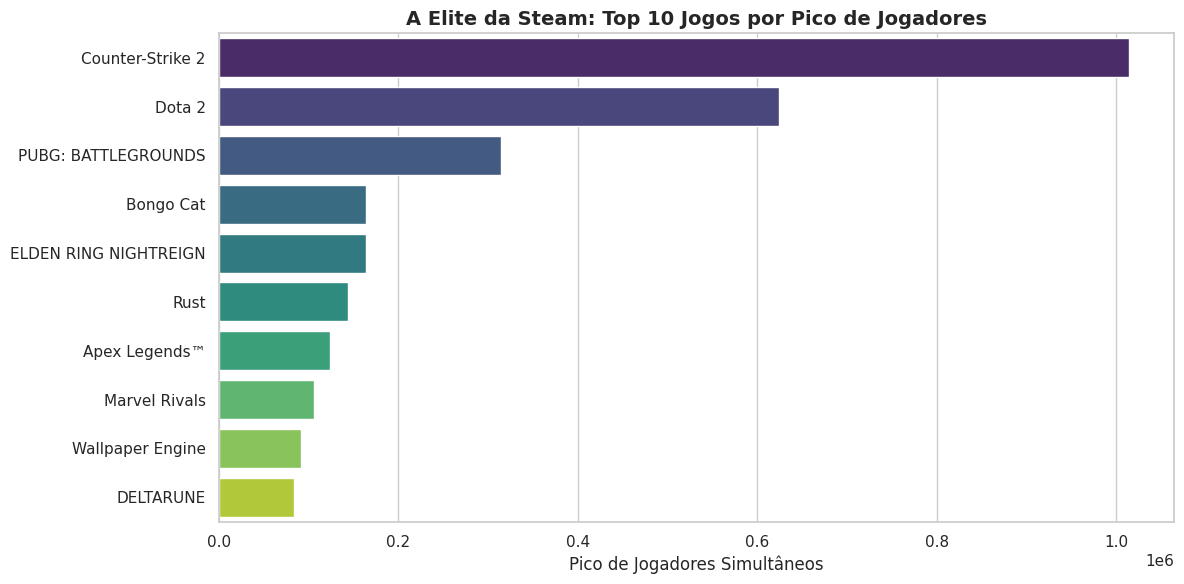

In [5]:
plt.figure(figsize=(12, 6))

top_10 = df.nlargest(10, 'Peak CCU')
sns.barplot(data=top_10, x='Peak CCU', y='Name', palette='viridis')

plt.title('A Elite da Steam: Top 10 Jogos por Pico de Jogadores', fontsize=14, weight='bold')
plt.xlabel('Pico de Jogadores Simultâneos', fontsize=12)
plt.ylabel('')
plt.tight_layout()
plt.show()

### **Insight 4:**

A análise do ranking dos dez maiores jogos da história da plataforma revela uma disparidade marcante entre os primeiros colocados e os demais títulos em termos de pico simultâneo de jogadores.

O destaque absoluto fica para Counter-Strike 2 e Dota 2, gigantes Free-to-Play desenvolvidos pela própria Valve. Ambos exemplificam o ápice do modelo Games as a Service (GaaS) aliado ao cenário de E-sports. São jogos projetados para uso contínuo, capazes de sustentar picos diários astronômicos graças à retenção de veteranos e à atração constante de novos jogadores.

Nas posições intermediárias do ranking, habitam grandes sucessos e fenômenos globais da indústria, que incluem desde RPGs de mundo aberto até produções AAA e fenômenos virais. A dinâmica desses títulos é diferente, já que são marcados pelo pico de lançamento. São produções de enorme impacto comercial que reúnem centenas de milhares (ou até milhões) de pessoas no primeiro mês, mas cujos números reduzem gradualmente conforme a comunidade conclui a campanha principal ou explora todo o conteúdo disponível.

Por fim, a presença de softwares como o Wallpaper Engine e títulos narrativos como DELTARUNE ilustra a diversidade do catálogo da Steam. O primeiro funciona como um utilitário de personalização executado em segundo plano, enquanto o segundo é uma experiência focada, linear e de curta duração. Ambos possuem comunidades leais e engajadas, mas a natureza de seus formatos não exige o mesmo volume de concorrência ou presença simultânea diária de uma arena competitiva.

# 5. O Domínio dos Gêneros: O que a Steam mais joga?

Para finalizar nossa análise, vamos descobrir quais são os gêneros que mais atraem jogadores simultâneos na plataforma. Como um único jogo pode pertencer a vários gêneros (ex: Ação e RPG), vamos separar essas categorias para ver quais acumulam o maior volume de jogadores de pico (Peak CCU).

/tmp/ipykernel_1758/2299634188.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=top_generos, x='Peak CCU', y='Genres', palette='magma')


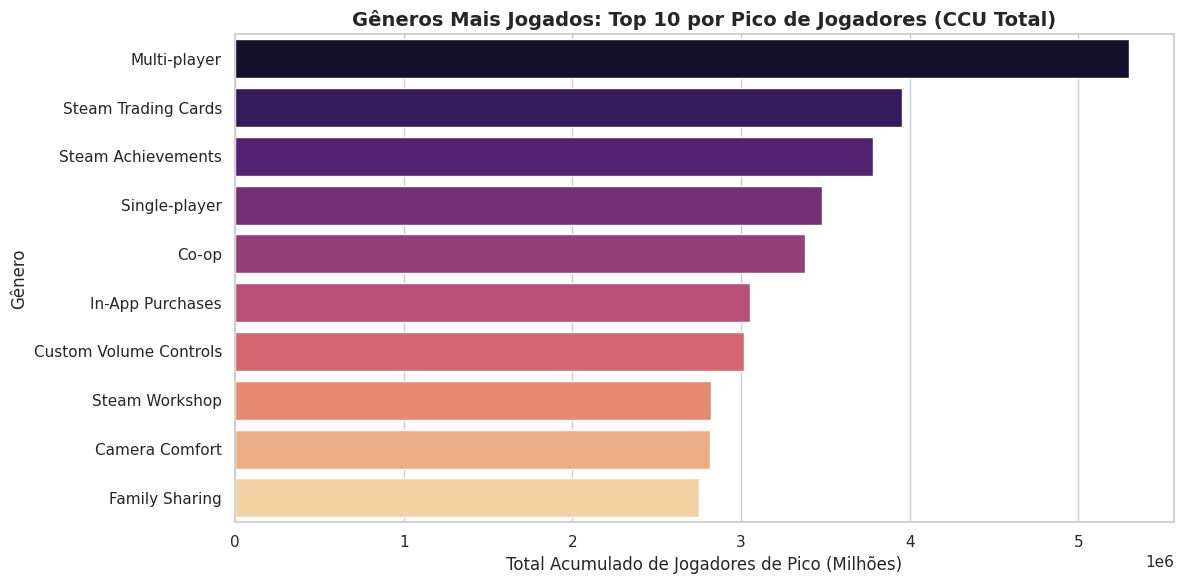

In [6]:
plt.figure(figsize=(12, 6))

# 1. Limpando jogos sem gênero definido e separando os gêneros por vírgula
df_generos = df.dropna(subset=['Genres']).copy()
df_generos['Genres'] = df_generos['Genres'].str.split(',')

# 2. O comando explode 'multiplica' a linha para cada gênero, permitindo contar individualmente
df_expandido = df_generos.explode('Genres')

# 3. Removendo espaços em branco extras que podem ficar após a vírgula
df_expandido['Genres'] = df_expandido['Genres'].str.strip()

# 4. Agrupando pelo Pico de Jogadores (Peak CCU) somado por gênero e pegando o Top 10
top_generos = df_expandido.groupby('Genres')['Peak CCU'].sum().nlargest(10).reset_index()

# 5. Plotando o gráfico de barras horizontais
ax = sns.barplot(data=top_generos, x='Peak CCU', y='Genres', palette='magma')

plt.title('Gêneros Mais Jogados: Top 10 por Pico de Jogadores (CCU Total)', fontsize=14, weight='bold')
plt.xlabel('Total Acumulado de Jogadores de Pico (Milhões)', fontsize=12)
plt.ylabel('Gênero', fontsize=12)

plt.tight_layout()
plt.show()

### **Insight 5:**

Ao analisar o acumulado de jogadores por categoria, o gráfico revela que o que realmente mobiliza as massas na Steam não é um estilo de jogo específico, mas sim a interação social e os sistemas de recompensa.


*   A Supremacia do Multiplayer e Co-op: A tag "Multi-player" lidera o ranking de forma isolada, ultrapassando a impressionante marca de 5 milhões no total acumulado de jogadores de pico. Somado à forte presença do formato "Co-op" (Cooperativo), que também aparece no top 5, fica evidente que experiências sociais e competitivas são o principal motor de engajamento da indústria no PC.

*   O Peso do "Metagaming" (Cartas e Conquistas): Um insight valioso é a força massiva de Steam Trading Cards e Steam Achievements, que ocupam o segundo e terceiro lugares, respectivamente. Isso demonstra que o engajamento do usuário vai muito além do gameplay, a comunidade valoriza imensamente a progressão do próprio perfil na plataforma, buscando colecionáveis, insígnias e "platinas".


*   Monetização e Retenção Estendida: A presença forte de "In-App Purchases" (Compras dentro do aplicativo) e "Steam Workshop" entre os mais jogados consolida a dominância dos Jogos como Serviço (GaaS). Títulos que possuem economias internas (como venda de skins) ou que permitem a instalação de modificações da comunidade (Mods via Workshop) garantem uma vida útil quase infinita, resultando em picos de jogadores contínuos ano após ano.

# - Conclusão da Análise Exploratória (EDA)

A análise histórica e comportamental da Steam revela que o sucesso na plataforma deixou de ser apenas sobre publicar um bom jogo, tornando-se um desafio estratégico de posicionamento. Com a transição de uma loja fechada para um mercado aberto, a concorrência explodiu, exigindo que estúdios entendam exatamente como a comunidade consome tempo e dinheiro.

O cruzamento dos dados nos deixa três diretrizes claras de mercado:

1.   A Retenção: O engajamento não cresce linearmente com o preço. A faixas médias de preço entrega o maior tempo médio de retenção (1.6h), provando que Premium Indies e títulos de alta rejogabilidade oferecem um custo-benefício que supera o engajamento médio dos grandes e caros lançamentos AAA (que caem para 0.4h).

2.   A Soberania do GaaS e do Fator Social: O topo absoluto da plataforma pertence a experiências contínuas e gratuitas (como CS2 e Dota 2). Além disso, a presença isolada da categoria "Multi-player" no topo do engajamento geral prova que a interação social é o maior motor de retenção do PC.

3.   O Poder do "Metagaming": A retenção a longo prazo está profundamente atrelada ao ecossistema da própria loja. O alto consumo de jogos com Steam Trading Cards, Achievements e Workshop demonstra que os jogadores valorizam a progressão do próprio perfil e a expansão de conteúdo gerada pela comunidade.

Em suma, o cenário atual premia a interação social, a alta rejogabilidade e o uso inteligente dos recursos da própria loja. Como próximo passo de pesquisa, essas métricas de retenção poderiam ser cruzadas com as avaliações (reviews) dos usuários, mapeando como o sentimento da comunidade dita a vida útil de um título ao longo dos anos.